In [32]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

def lorenz_rhs(t, state, sigma=10.0, rho=28.0, beta=8.0/3.0):
    """Right-hand side of the Lorenz system."""
    x, y, z = state
    # TODO: write the three derivatives here, following the equations above
    dx = sigma * (y - x)
    dy = x * (rho - z) - y
    dz = x * y - beta * z
    return [dx, dy, dz]

# Integrate a trajectory
# Lorenz is usually integrated with a fixed small timestep for ML work,
# because the reservoir needs evenly-spaced samples.
dt = 0.02
t_max = 250.0
t_eval = np.arange(0, t_max, dt)

initial_state = [1.0, 1.0, 1.0]  # arbitrary starting point

sol = solve_ivp(
    lorenz_rhs, (0, t_max), initial_state,
    t_eval=t_eval, method='RK45', rtol=1e-9, atol=1e-9
)

# sol.y is shape (3, num_timesteps) — the trajectory
data = sol.y.T  # transpose to (num_timesteps, 3) — each row is a state
print(f"Generated {data.shape[0]} timesteps of Lorenz data, each {data.shape[1]}-dimensional")

Generated 12500 timesteps of Lorenz data, each 3-dimensional


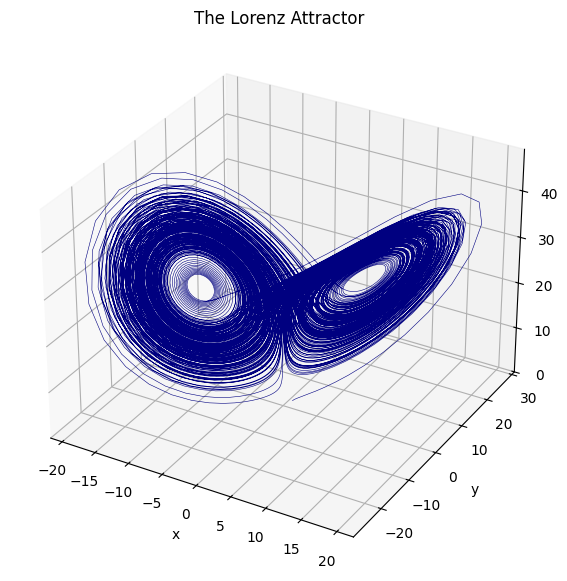

In [33]:
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')
ax.plot(data[:, 0], data[:, 1], data[:, 2], linewidth=0.4, color='navy')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')
ax.set_title('The Lorenz Attractor')
plt.show()

In [34]:
# Normalize the Lorenz data so each variable has ~zero mean and unit std.
# This keeps the reservoir's tanh argument in its useful range.
data_mean = data.mean(axis=0)
data_std = data.std(axis=0)
data_normalized = (data - data_mean) / data_std

print("Before normalization — ranges:")
print(f"  x: [{data[:,0].min():.1f}, {data[:,0].max():.1f}]")
print(f"  y: [{data[:,1].min():.1f}, {data[:,1].max():.1f}]")
print(f"  z: [{data[:,2].min():.1f}, {data[:,2].max():.1f}]")
print("After normalization — ranges:")
print(f"  x: [{data_normalized[:,0].min():.1f}, {data_normalized[:,0].max():.1f}]")
print(f"  y: [{data_normalized[:,1].min():.1f}, {data_normalized[:,1].max():.1f}]")
print(f"  z: [{data_normalized[:,2].min():.1f}, {data_normalized[:,2].max():.1f}]")

# === Reservoir hyperparameters ===
N = 300              # number of reservoir nodes (size of the "pond")
spectral_radius = 0.9   # largest eigenvalue magnitude of W — the key parameter
sparsity = 0.1       # fraction of nonzero connections in W (10%)
input_scaling = 1.0  # how strongly input drives the reservoir
seed = 42            # for reproducibility

rng = np.random.default_rng(seed)

# --- Build W: the reservoir's internal connections ---
# Start with a random matrix, then make it sparse, then scale its spectral radius.
W = rng.uniform(-1, 1, size=(N, N))

# Make it sparse: keep only `sparsity` fraction of connections, zero the rest
mask = rng.uniform(0, 1, size=(N, N)) < sparsity
W = W * mask

# Scale so the spectral radius equals our target.
# The spectral radius is the largest absolute eigenvalue.
current_radius = np.max(np.abs(np.linalg.eigvals(W)))
W = W * (spectral_radius / current_radius)

# Verify the scaling worked
print(f"Target spectral radius: {spectral_radius}")
print(f"Actual spectral radius: {np.max(np.abs(np.linalg.eigvals(W))):.4f}")

# --- Build W_in: maps 3D input into N-dimensional reservoir ---
W_in = rng.uniform(-input_scaling, input_scaling, size=(N, 3))

print(f"\nReservoir built: W is {W.shape}, W_in is {W_in.shape}")

Before normalization — ranges:
  x: [-18.9, 19.5]
  y: [-25.8, 27.2]
  z: [1.0, 47.8]
After normalization — ranges:
  x: [-2.3, 2.5]
  y: [-2.8, 3.1]
  z: [-2.7, 2.8]
Target spectral radius: 0.9
Actual spectral radius: 0.9000

Reservoir built: W is (300, 300), W_in is (300, 3)


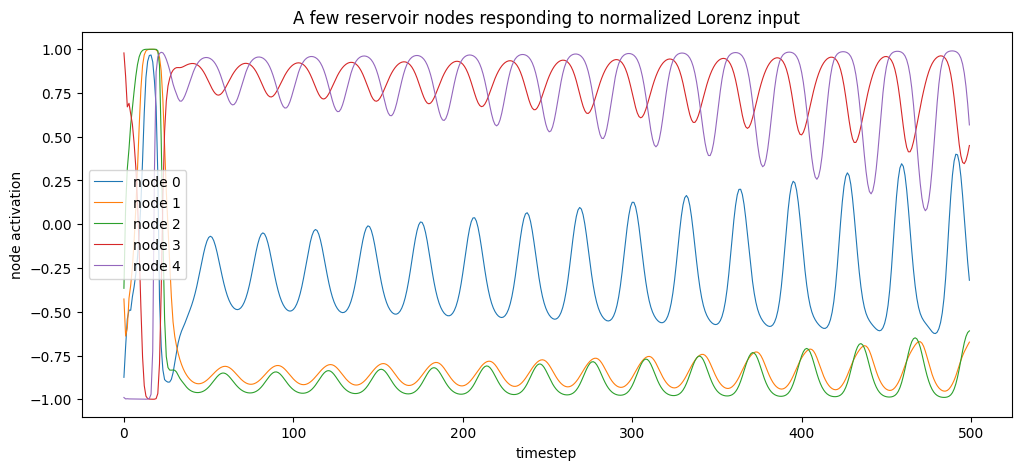

In [35]:
def reservoir_update(r, u, W, W_in):
    """Advance the reservoir one timestep.
    
    r : current reservoir state, shape (N,)
    u : current input, shape (3,)
    Returns the new reservoir state, shape (N,).
    """
    return np.tanh(W @ r + W_in @ u)

# Drive the reservoir with the first 500 steps of Lorenz data and record states
N_test = 500
r = np.zeros(N)              # start the reservoir at rest
states = np.zeros((N_test, N))
for i in range(N_test):
    r = reservoir_update(r, data_normalized [i], W, W_in)
    states[i] = r

# Plot a few reservoir node activities over time
fig, ax = plt.subplots(figsize=(12, 5))
for node in range(5):   # just show 5 of the 300 nodes
    ax.plot(states[:, node], linewidth=0.8, label=f'node {node}')
ax.set_xlabel('timestep')
ax.set_ylabel('node activation')
ax.set_title('A few reservoir nodes responding to normalized Lorenz input')
ax.legend()
plt.show()

In [36]:
# === Split data into training and testing portions ===
# We train on a long stretch, then test prediction on what comes after.
washout = 1000        # discard this many initial steps (reservoir transient)
train_len = 8000     # steps used for training the readout
# (testing happens later, in Phase 3, on the data right after training)

# Use the normalized data throughout
u_data = data_normalized

# === Drive the reservoir across the training span, collecting states ===
r = np.zeros(N)
# We'll store the reservoir state at each step, and the TARGET (next input).
collected_states = []
collected_targets = []

for i in range(train_len):
    r = reservoir_update(r, u_data[i], W, W_in)
    if i >= washout:                     # only keep states after washout
        collected_states.append(r.copy())
        collected_targets.append(u_data[i + 1])   # the NEXT state is the target

# Convert to arrays
R = np.array(collected_states)    # shape (train_len - washout, N)
Y = np.array(collected_targets)   # shape (train_len - washout, 3)

print(f"Collected {R.shape[0]} training pairs")
print(f"Reservoir states R: {R.shape}")
print(f"Targets Y:          {Y.shape}")

Collected 7000 training pairs
Reservoir states R: (7000, 300)
Targets Y:          (7000, 3)


In [37]:
# Ridge regression to find W_out: maps reservoir state -> next Lorenz state.
beta = 1e-6   # regularization strength (small)

# Solve W_out^T = (R^T R + beta*I)^{-1} R^T Y
RtR = R.T @ R                          # (N, N)
RtY = R.T @ Y                          # (N, 3)
W_out = np.linalg.solve(RtR + beta * np.eye(N), RtY).T   # shape (3, N)

print(f"Trained W_out: {W_out.shape}")

# Sanity check: how well does it fit the TRAINING data?
# (This is in-sample fit — not yet a real test, but confirms training worked.)
Y_pred_train = (W_out @ R.T).T         # predictions on training states
train_rmse = np.sqrt(np.mean((Y_pred_train - Y)**2))
print(f"Training RMSE (normalized units): {train_rmse:.4f}")

Trained W_out: (3, 300)
Training RMSE (normalized units): 0.0003


In [38]:
# === Phase 3: Autonomous prediction ===
# Start where training ended. First, "warm up" the reservoir on a short stretch
# of real data right after the training span, so its state reflects real dynamics.

predict_len = 2000       # how many steps to predict autonomously
warmup_start = train_len # start right after training data
warmup_steps = 200       # short re-warmup on real data to set reservoir state

# Re-warm the reservoir on real data just before the prediction start point
r = np.zeros(N)
for i in range(warmup_start - warmup_steps, warmup_start):
    r = reservoir_update(r, u_data[i], W, W_in)

# Now predict autonomously: feed the reservoir's OWN output back as input
predictions = np.zeros((predict_len, 3))
u = u_data[warmup_start]   # the last real input to kick things off
for i in range(predict_len):
    r = reservoir_update(r, u, W, W_in)   # advance reservoir
    pred = W_out @ r                       # predict next state (normalized units)
    predictions[i] = pred
    u = pred                               # FEED PREDICTION BACK as next input

# The TRUE trajectory over the same span, for comparison
truth = u_data[warmup_start : warmup_start + predict_len]

print(f"Generated {predict_len} autonomous prediction steps")
print(f"Predictions shape: {predictions.shape}, Truth shape: {truth.shape}")

Generated 2000 autonomous prediction steps
Predictions shape: (2000, 3), Truth shape: (2000, 3)


In [39]:
# Diagnostic 1: one-step-ahead prediction using TRUE inputs (no feedback)
# Drive reservoir on real data, predict next step, compare to actual next step.
r = np.zeros(N)
warmup_steps = 1000
for i in range(warmup_start - warmup_steps, warmup_start):
    r = reservoir_update(r, u_data[i], W, W_in)

onestep_preds = np.zeros((predict_len, 3))
for i in range(predict_len):
    idx = warmup_start + i
    r = reservoir_update(r, u_data[idx], W, W_in)   # TRUE input, not prediction
    onestep_preds[i] = W_out @ r

truth_compare = u_data[warmup_start : warmup_start + predict_len]
onestep_rmse = np.sqrt(np.mean((onestep_preds - truth_compare)**2))
print(f"One-step-ahead RMSE (true inputs, normalized): {onestep_rmse:.4f}")

One-step-ahead RMSE (true inputs, normalized): 0.1530


In [40]:
# === Self-contained: longer-washout training + one-step test ===
washout = 1000
train_len = 8000
warmup_start = train_len

# --- Train ---
r = np.zeros(N)
collected_states = []
collected_targets = []
for i in range(train_len):
    r = reservoir_update(r, u_data[i], W, W_in)
    if i >= washout:
        collected_states.append(r.copy())
        collected_targets.append(u_data[i + 1])

R = np.array(collected_states)
Y = np.array(collected_targets)
print(f"Training pairs collected: {R.shape[0]}  (should be {train_len - washout})")

beta = 1e-6
W_out = np.linalg.solve(R.T @ R + beta * np.eye(N), R.T @ Y).T
train_rmse = np.sqrt(np.mean(((W_out @ R.T).T - Y)**2))
print(f"Training RMSE: {train_rmse:.5f}")

# --- One-step test ---
r = np.zeros(N)
warmup_steps = 1000
for i in range(warmup_start - warmup_steps, warmup_start):
    r = reservoir_update(r, u_data[i], W, W_in)

onestep_preds = np.zeros((2000, 3))
for i in range(2000):
    idx = warmup_start + i
    r = reservoir_update(r, u_data[idx], W, W_in)
    onestep_preds[i] = W_out @ r

truth_compare = u_data[warmup_start : warmup_start + 2000]
onestep_rmse = np.sqrt(np.mean((onestep_preds - truth_compare)**2))
print(f"One-step-ahead RMSE: {onestep_rmse:.5f}")

Training pairs collected: 7000  (should be 7000)
Training RMSE: 0.00030
One-step-ahead RMSE: 0.15302


In [41]:
# --- One-step test (corrected alignment) ---
r = np.zeros(N)
warmup_steps = 1000
for i in range(warmup_start - warmup_steps, warmup_start):
    r = reservoir_update(r, u_data[i], W, W_in)

onestep_preds = np.zeros((2000, 3))
onestep_truth = np.zeros((2000, 3))
for i in range(2000):
    idx = warmup_start + i
    r = reservoir_update(r, u_data[idx], W, W_in)   # absorb u_data[idx]
    onestep_preds[i] = W_out @ r                     # predicts u_data[idx + 1]
    onestep_truth[i] = u_data[idx + 1]               # the correct target: NEXT step

onestep_rmse = np.sqrt(np.mean((onestep_preds - onestep_truth)**2))
print(f"One-step-ahead RMSE (corrected): {onestep_rmse:.5f}")

One-step-ahead RMSE (corrected): 0.00029


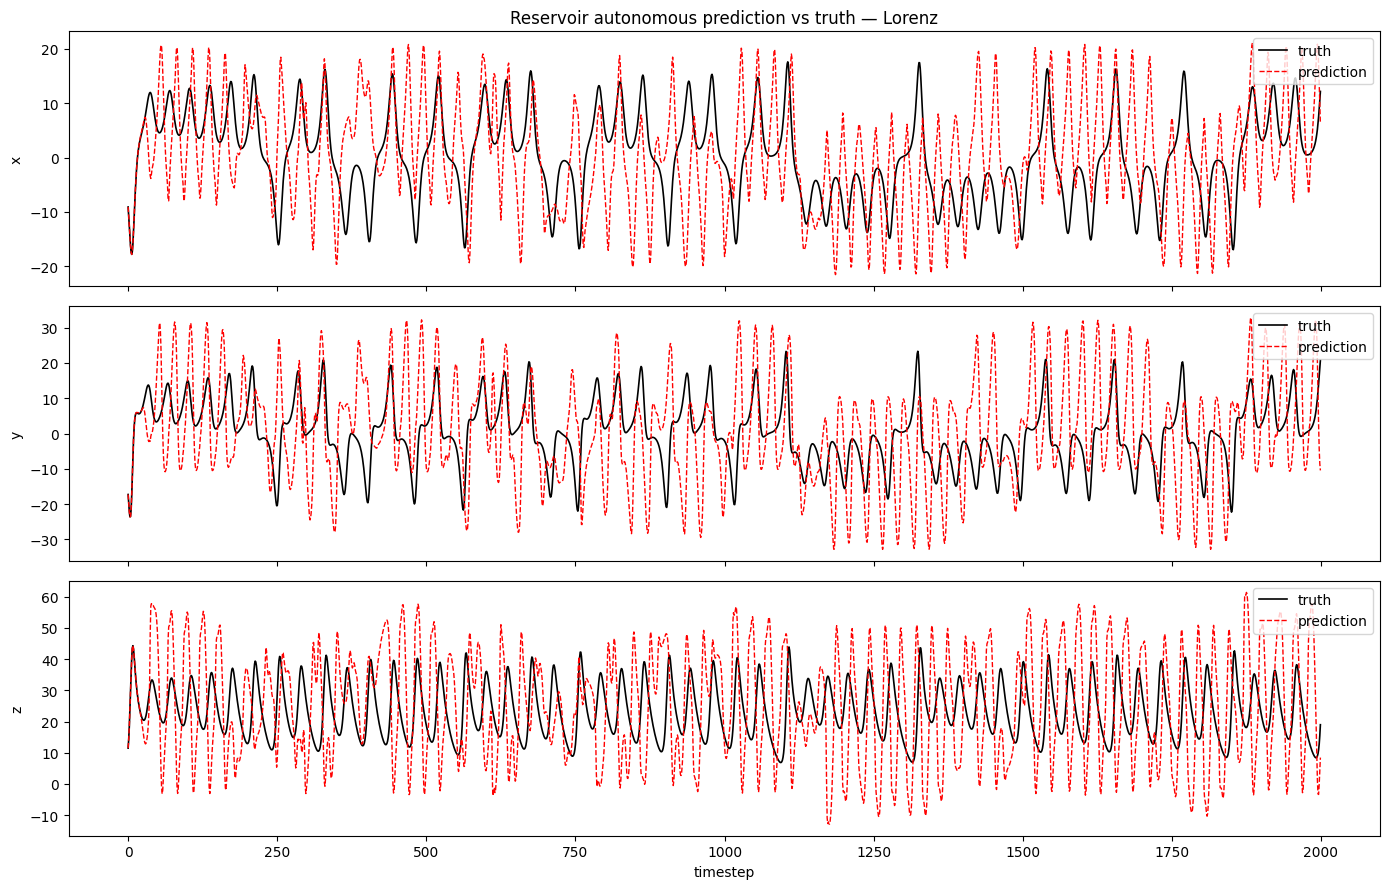

In [42]:
# === Phase 3: Autonomous prediction (clean, current W_out) ===
predict_len = 2000
warmup_steps = 1000

# Re-warm the reservoir on real data just before the prediction start
r = np.zeros(N)
for i in range(warmup_start - warmup_steps, warmup_start):
    r = reservoir_update(r, u_data[i], W, W_in)

# Autonomous generation: feed each prediction back as the next input
predictions = np.zeros((predict_len, 3))
u = u_data[warmup_start]      # kick off with the last real input
for i in range(predict_len):
    r = reservoir_update(r, u, W, W_in)   # absorb current input
    pred = W_out @ r                       # predict next state
    predictions[i] = pred
    u = pred                               # feed prediction back

# True trajectory over the same span — aligned to what we predict.
# predictions[i] is the model's guess for u_data[warmup_start + i + 1].
truth = u_data[warmup_start + 1 : warmup_start + 1 + predict_len]

# Back to real Lorenz units
predictions_real = predictions * data_std + data_mean
truth_real = truth * data_std + data_mean

# Plot truth vs prediction for each variable
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
labels = ['x', 'y', 'z']
for k in range(3):
    axes[k].plot(truth_real[:, k], 'k-', linewidth=1.2, label='truth')
    axes[k].plot(predictions_real[:, k], 'r--', linewidth=1.0, label='prediction')
    axes[k].set_ylabel(labels[k])
    axes[k].legend(loc='upper right')
axes[0].set_title('Reservoir autonomous prediction vs truth — Lorenz')
axes[-1].set_xlabel('timestep')
plt.tight_layout()
plt.show()

In [43]:
# Measure how prediction error grows step-by-step in the autonomous run
errors = np.linalg.norm(predictions - truth, axis=1)  # error magnitude at each step
for i in [0, 1, 2, 3, 5, 8, 10, 15, 20, 30, 50]:
    if i < len(errors):
        print(f"step {i:3d}: error = {errors[i]:.4f}")

step   0: error = 0.0013
step   1: error = 0.0027
step   2: error = 0.0052
step   3: error = 0.0079
step   5: error = 0.0146
step   8: error = 0.0189
step  10: error = 0.0171
step  15: error = 0.0228
step  20: error = 0.0515
step  30: error = 1.4941
step  50: error = 3.3174


In [44]:
# Retrain with stronger regularization and re-test autonomous tracking.
for beta_try in [1e-6, 1e-4, 1e-2, 1e-1, 1.0]:
    # Retrain readout with this beta (R, Y already collected from cell 9)
    W_out_try = np.linalg.solve(R.T @ R + beta_try * np.eye(N), R.T @ Y).T

    # Autonomous run
    r = np.zeros(N)
    for i in range(warmup_start - 1000, warmup_start):
        r = reservoir_update(r, u_data[i], W, W_in)
    preds = np.zeros((predict_len, 3))
    u = u_data[warmup_start]
    for i in range(predict_len):
        r = reservoir_update(r, u, W, W_in)
        p = W_out_try @ r
        preds[i] = p
        u = p
    tru = u_data[warmup_start + 1 : warmup_start + 1 + predict_len]

    # How many steps until error exceeds a threshold (say 0.5 in normalized units)?
    errs = np.linalg.norm(preds - tru, axis=1)
    over = np.where(errs > 0.5)[0]
    track_steps = over[0] if len(over) > 0 else predict_len
    print(f"beta={beta_try:.0e}: tracked {track_steps} steps before error > 0.5")

beta=1e-06: tracked 26 steps before error > 0.5
beta=1e-04: tracked 25 steps before error > 0.5
beta=1e-02: tracked 25 steps before error > 0.5
beta=1e-01: tracked 54 steps before error > 0.5
beta=1e+00: tracked 25 steps before error > 0.5


In [45]:
# === Augmented readout: predict from [1, u, r] instead of r alone ===

def augment(u, r):
    """Stack a constant bias, the input, and the reservoir state into one vector."""
    return np.concatenate(([1.0], u, r))   # length 1 + 3 + N

# --- Re-collect training data with augmented features ---
washout = 1000
train_len = 8000
warmup_start = train_len

r = np.zeros(N)
aug_states = []
targets = []
for i in range(train_len):
    r = reservoir_update(r, u_data[i], W, W_in)
    if i >= washout:
        aug_states.append(augment(u_data[i], r))   # [1, u_i, r] AFTER absorbing u_i
        targets.append(u_data[i + 1])               # predict next state

A = np.array(aug_states)     # shape (7000, 304)
Y = np.array(targets)        # shape (7000, 3)
print(f"Augmented feature matrix A: {A.shape}")

# --- Sweep beta, train augmented readout, test autonomous tracking ---
M = A.shape[1]   # 304
for beta_try in [1e-8, 1e-6, 1e-4, 1e-2, 1e-1]:
    W_out_aug = np.linalg.solve(A.T @ A + beta_try * np.eye(M), A.T @ Y).T  # (3, 304)

    # Autonomous run with augmented readout
    r = np.zeros(N)
    for i in range(warmup_start - 1000, warmup_start):
        r = reservoir_update(r, u_data[i], W, W_in)
    preds = np.zeros((predict_len, 3))
    u = u_data[warmup_start]
    for i in range(predict_len):
        r = reservoir_update(r, u, W, W_in)
        p = W_out_aug @ augment(u, r)    # predict from [1, u, r]
        preds[i] = p
        u = p
    tru = u_data[warmup_start + 1 : warmup_start + 1 + predict_len]
    errs = np.linalg.norm(preds - tru, axis=1)
    over = np.where(errs > 0.5)[0]
    track_steps = over[0] if len(over) > 0 else predict_len
    print(f"beta={beta_try:.0e}: tracked {track_steps} steps")

Augmented feature matrix A: (7000, 304)
beta=1e-08: tracked 35 steps
beta=1e-06: tracked 50 steps
beta=1e-04: tracked 58 steps
beta=1e-02: tracked 43 steps
beta=1e-01: tracked 106 steps
